# Global stability

Run all cells with the `silscore` environment; the included caches are sufficient.

Generated from [nb3_global_stability.py](nb3_global_stability.py).

In [1]:
"""Plot cached global-stability diagnostics.

Read the NPZ cache and export the figure in raster and vector formats.
"""
from __future__ import annotations

from pathlib import Path

import matplotlib.lines as mlines
import matplotlib.pyplot as plt
from IPython.display import Image
import numpy as np

def _resolve_root() -> Path:
    file_name = globals().get("__file__")
    if file_name:
        return Path(file_name).resolve().parents[1]
    cwd = Path.cwd().resolve()
    if (cwd / "data" / "cache").is_dir():
        return cwd
    if cwd.name == "notebooks" and (cwd.parent / "data" / "cache").is_dir():
        return cwd.parent
    raise RuntimeError("cannot resolve Silscore root from __file__ or cwd")


ROOT = _resolve_root()
CACHE = ROOT / "data" / "cache" / "global_stability.npz"
OUT = ROOT / "output" / "figures"
FIG_W = 402 / 72  # PDF points converted to inches.
COLORS = {"huesken": "#2F67B2", "mixset": "#8B5FBF", "taka": "#269E75"}
LABELS = {"huesken": "Huesken", "mixset": "Mixset", "taka": "KS"}
X_LIM, Y_LIM = (-50.5, -18.5), (-3.42, 0.85)

def load_cache() -> np.lib.npyio.NpzFile:
    if not CACHE.is_file():
        raise FileNotFoundError(f"missing {CACHE}; run python scripts/reproduce.py --overwrite")
    data = np.load(CACHE, allow_pickle=False)
    if int(data.get("B_BOOT", np.asarray([-1]))[0]) != 4000:
        data.close(); raise ValueError("global cache requires B_BOOT=4000")
    if int(data.get("SEME", np.asarray([-1]))[0]) != 0:
        data.close(); raise ValueError("global cache requires SEME=0")
    for key in ("huesken", "mixset", "taka"):
        required = (f"{key}_x_curve", f"{key}_y_curve", f"{key}_x_central",
                    f"{key}_y_central", f"{key}_bin_x", f"{key}_bin_y",
                    f"{key}_bin_lo", f"{key}_bin_hi", f"{key}_hist_edges",
                    f"{key}_hist_pct", f"{key}_vertex", f"{key}_n")
        missing = [name for name in required if name not in data]
        if missing:
            data.close(); raise ValueError(f"cache missing {missing}")
    return data

def panel(ax, hist_ax, data, key: str, letter: str, hist_letter: str) -> None:
    color = COLORS[key]; x = data[f"{key}_x_curve"]; y = data[f"{key}_y_curve"]
    xc = data[f"{key}_x_central"]; yc = data[f"{key}_y_central"]
    bx, by = data[f"{key}_bin_x"], data[f"{key}_bin_y"]
    blo, bhi = data[f"{key}_bin_lo"], data[f"{key}_bin_hi"]
    vertex = float(data[f"{key}_vertex"][0]); n = int(data[f"{key}_n"][0])
    ax.plot(x, y, color=color, lw=1.2, ls=(0, (3, 2)), alpha=0.85, zorder=2)
    ax.plot(xc, yc, color=color, lw=1.55, zorder=3)
    ax.axvline(vertex, color=color, lw=0.75, ls=(0, (2, 2)), alpha=0.65, zorder=1)
    ax.text(vertex - 0.45, Y_LIM[0] + 0.08, f"$\\Delta G^*={vertex:.1f}$", color=color,
            fontsize=6.3, ha="right", va="bottom",
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.78, "pad": 0.15})
    ax.errorbar(bx, by, yerr=[by - blo, bhi - by], fmt="o", color=color,
                markerfacecolor=color, markeredgecolor="white", markeredgewidth=1.05,
                markersize=3.8, ecolor="0.35", elinewidth=0.65, capsize=0, zorder=5)
    if f"{key}_bin0_y" in data:
        ax.plot(bx, data[f"{key}_bin0_y"], linestyle="none", marker="x", color="0.42",
                markersize=3.5, markeredgewidth=0.70, zorder=6)
    if f"{key}_x_extra" in data:
        ax.plot(data[f"{key}_x_extra"], data[f"{key}_y_extra"], color=color,
                lw=1.2, ls=(0, (3, 2)), alpha=0.9, zorder=3)
        ax.plot(float(data[f"{key}_vertex"][0]), float(data[f"{key}_vertex_y"][0]),
                marker="D", ms=3.5, markerfacecolor="white", markeredgecolor=color,
                markeredgewidth=0.9, zorder=4)
    ax.axhline(0, color="0.48", lw=0.7, zorder=0)
    ax.set_xlim(-50.5, -18.5); ax.set_ylim(*Y_LIM); ax.set_xticks([-50, -40, -30, -20])
    ax.grid(axis="both", alpha=0.18, zorder=-3); ax.tick_params(labelsize=7.5, length=2.5)
    ax.set_title(f"{letter}   {LABELS[key]} ($n={n}$)", loc="left", fontsize=8.0, pad=4)
    ax.set_box_aspect(1)
    edges = data[f"{key}_hist_edges"]
    hist_ax.bar(edges[:-1], data[f"{key}_hist_pct"], width=np.diff(edges), align="edge",
                color=color, alpha=0.72, edgecolor="white", linewidth=0.35)
    hist_ax.axvline(vertex, color=color, lw=0.75, ls=(0, (2, 2)), alpha=0.65, zorder=3)
    hist_ax.set_xlim(-50.5, -18.5); hist_ax.set_xticks([-50, -40, -30, -20])
    hist_ax.grid(axis="both", alpha=0.18, zorder=-3); hist_ax.tick_params(labelsize=7.5, length=2.5)
    hist_ax.set_xlabel("total duplex $\\Delta G$\n(kcal/mol)", fontsize=8.5)
    hist_ax.set_title(hist_letter, loc="left", fontsize=8.0, pad=4); hist_ax.set_box_aspect(1)

def main() -> int:
    data = load_cache()
    fig, axes = plt.subplots(2, 3, figsize=(FIG_W, 4.30), dpi=300, sharex="col", sharey="row")
    for ax, hist_ax, key, letter, hist_letter in zip(axes[0], axes[1],
                                                       ("huesken", "mixset", "taka"), "ABC", "DEF"):
        panel(ax, hist_ax, data, key, letter, hist_letter)
    axes[0, 0].set_ylabel("efficacy residual $R_j^{(G)}$\n(SD of efficacy)", fontsize=8.5)
    axes[1, 0].set_ylabel("guides per bin (%)", fontsize=8.5)
    legend = [
        mlines.Line2D([], [], color="0.25", lw=1.4, label=r"$-\kappa(\Delta G-\Delta G^*)^2$"),
        mlines.Line2D([], [], color="0.25", marker="o", mfc="0.25", mec="white", mew=1.05,
                      lw=0, ms=3.8, label=r"$R_j^{(G,\,\mathrm{with})}$"),
        mlines.Line2D([], [], color="0.42", marker="x", mew=0.70, lw=0, ms=3.5,
                      label=r"$R_j^{(G,\,\mathrm{without})}$"),
    ]
    fig.legend(handles=legend, frameon=False, fontsize=6.8, ncol=3,
               loc="upper center", bbox_to_anchor=(0.53, 0.995), handlelength=1.4,
               columnspacing=0.75)
    fig.subplots_adjust(left=0.115, right=0.99, bottom=0.15, top=0.90, wspace=0.10, hspace=0.24)
    OUT.mkdir(parents=True, exist_ok=True)
    for ext in ("pdf", "png"):
        fig.savefig(OUT / f"fig_global_stability.{ext}", dpi=300)
    plt.close(fig); data.close()
    print(f"wrote {OUT}/fig_global_stability.pdf and .png")
    return 0

wrote ./output/figures/fig_global_stability.pdf and .png


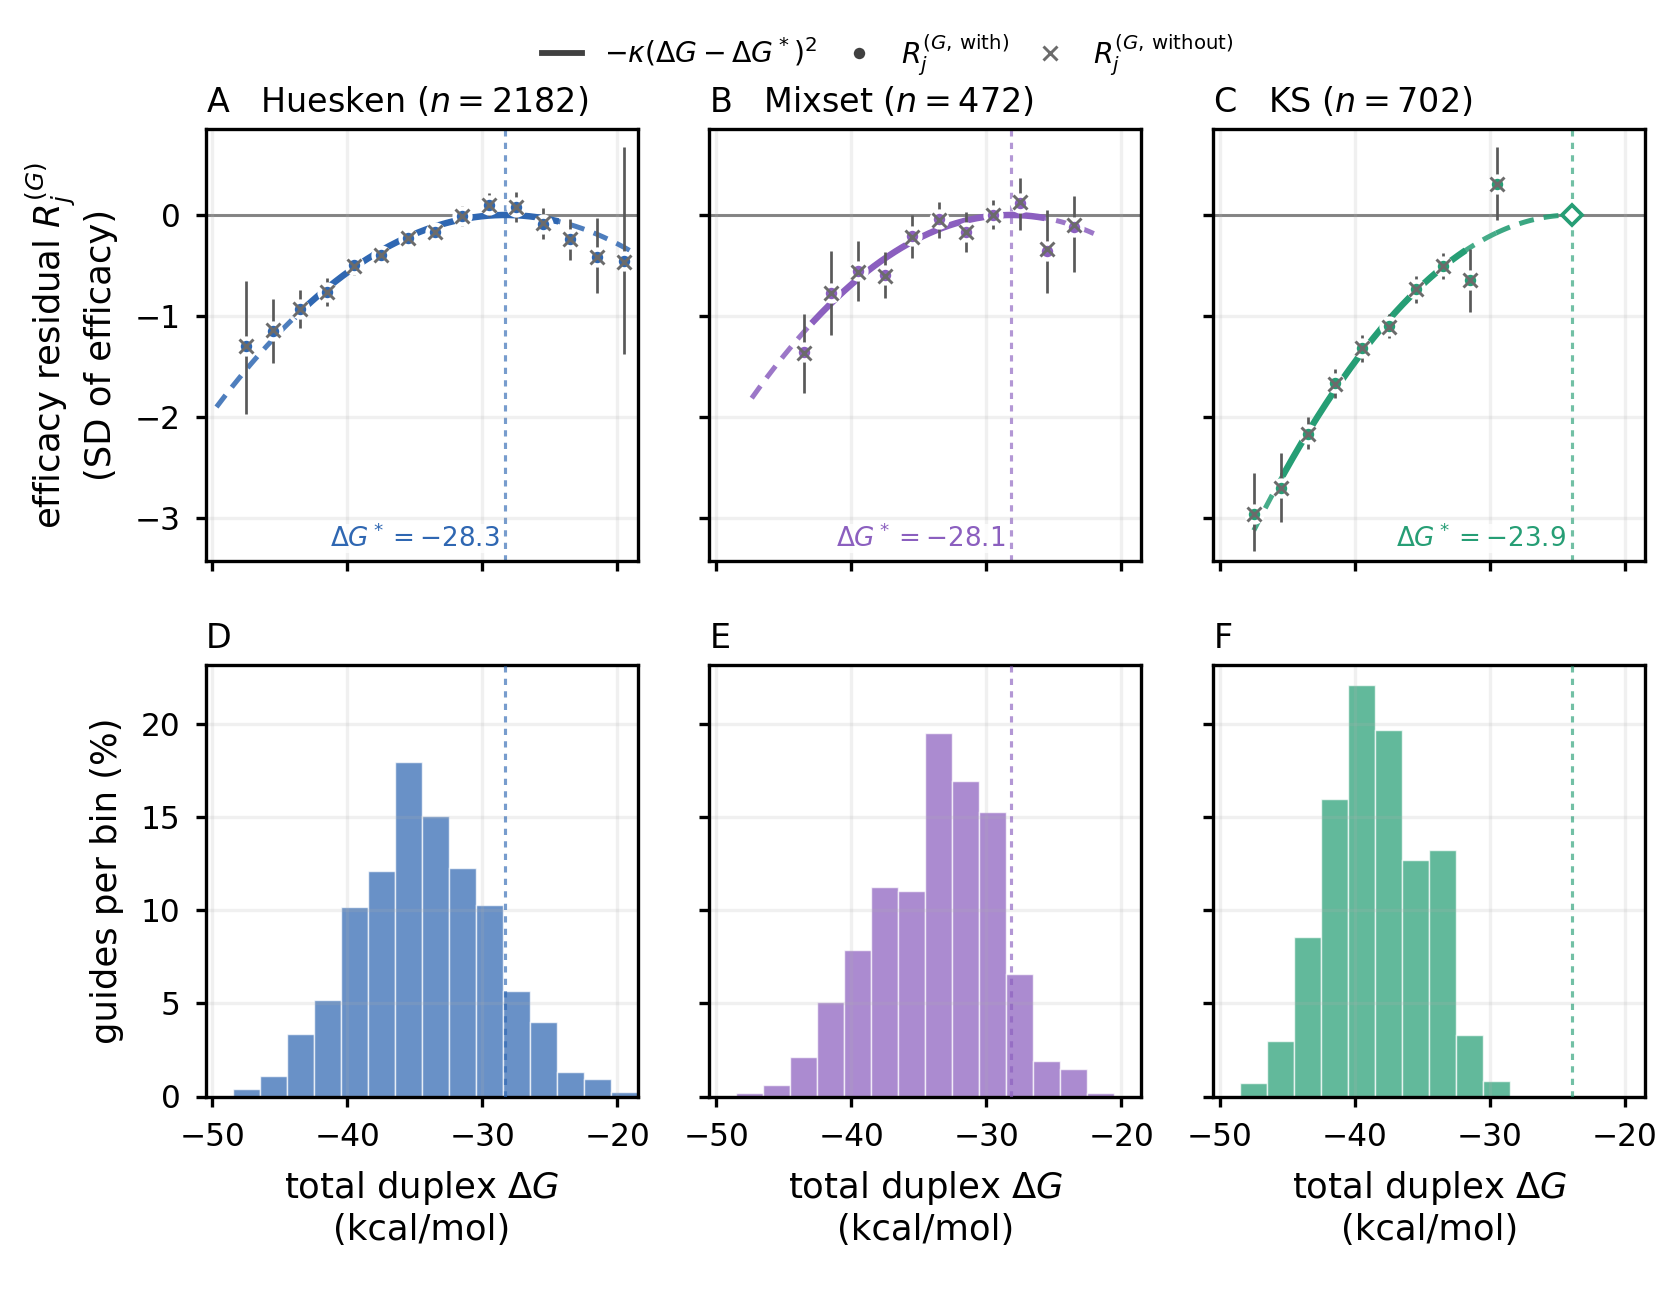

In [2]:
main()
Image(filename=str(ROOT / "output" / "figures" / "fig_global_stability.png"))